# 09 LSTM: final results

The LSTM baseline: a 2 layer bidirectional LSTM over per-frame pose features, no graph structure and no
attention, the simplest of the four models. Its job is to show what a plain sequence model gets on this
task, as a floor for ST-GCN, the Transformer Encoder and ST-TR to be compared against.

**Input.** `body_court`, the representation kept from the ST-GCN experiments (hip centred, body height
scaled, with court position as extra channels) since notebook 08 showed it costs nothing against raw
pixels and is more stable across seeds. Every joint's (x, y, confidence, bone dx, bone dy, court x, court
y) is flattened into one 119 dimensional vector per frame; the model reads the resulting 30 step sequence
in both time directions and classifies from the final hidden state.

**Recipe.** LSTMs do not share ST-GCN's sensitivities (no graph convolution, no need for the SGD plus
StepLR regime that suited it), so this uses a standard, literature typical recipe for a small recurrent
classifier rather than a repeated tuning search: Adam, cosine annealing, light weight decay, dropout in the
recurrent stack and before the classifier head. The class balanced sampler floor (300 per class) and
advanced augmentation policy are carried over unchanged, since those are properties of the data pipeline,
not the model.

**Scope.** 3 seeds (42, 123, 7) times 2 augmentation conditions (advanced, none): 6 runs. Every run reports
on train, val and test, with the same tracking as every model so far: per epoch curves, confusion matrix,
per class table, and predictions/checkpoint artifacts, logged to `BadmintonPoseAnalysis/models/LSTM`.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
sys.path.insert(0, REPO)
import dataset as ds
from models import lstm as lstm_model
import training as tr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/models/LSTM"
KEYPOINTS = f"{DATA}/keypoints_interp"
OUT = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs") + "/models/lstm"
os.makedirs(OUT, exist_ok=True)

SEEDS = [42, 123, 7]
SPLITS = ("train", "val", "test")
NORMALISATION, USE_COURT = "body", True
NUM_WORKERS, EVAL_WORKERS = 20, 8

RECIPE = {
    "model": "LSTM", "normalisation": "body_court", "hidden_size": 256, "num_layers": 2, "dropout": 0.3,
    "min_native_frames": 5, "batch_size": 32, "lr": 1e-3, "weight_decay": 1e-4, "label_smoothing": 0.0,
    "num_epochs": 60, "patience": 15, "select_metric": "top1", "target_per_class": 300,
}
CONDITIONS = {"advanced": "advanced", "none": "none"}

# reference points for the comparison plot: ST-GCN headline result and the no-motion probe (01_data_audit)
STGCN_FINAL = {"top1": 0.7229, "top1_std": 0.0106, "top5": 0.9437, "mca": 0.6121, "mca_std": 0.0133}
NO_MOTION_PROBE = {"top1": 0.549, "mca": 0.429}

In [3]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]
forward = lstm_model.make_forward(USE_COURT)
in_features = lstm_model.in_features(USE_COURT)

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)


## Smoke test

Run alone first: builds the model, checks the flattened input shape, one forward/backward pass, and that
every parameter gets a gradient (LSTMs can silently leave a layer disconnected if the input is reshaped
wrong).

In [4]:
tr.seed_everything(0)
loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, "advanced", NORMALISATION, seed=0, batch_size=RECIPE["batch_size"], target_per_class=300,
                           num_workers=2, eval_workers=2)
model = lstm_model.build_lstm(in_features, len(class_names), RECIPE["hidden_size"], RECIPE["num_layers"],
                              RECIPE["dropout"]).to(device)
print(f"in_features {in_features}, parameters {sum(p.numel() for p in model.parameters()):,}")

batch = next(iter(loaders["train"]))
logits = forward(model, batch, device)
assert logits.shape == (RECIPE["batch_size"], len(class_names)), logits.shape
nn.CrossEntropyLoss()(logits, batch["label"].to(device)).backward()
missing = [n for n, p in model.named_parameters() if p.requires_grad and p.grad is None]
assert not missing, missing

before = tr.evaluate(model, loaders["val"], forward, device)
print(f"untrained val top1 {before['top1']:.3f}")
del model, loaders
print("smoke test passed")

in_features 119, parameters 2,359,314
untrained val top1 0.041
smoke test passed


## Runs

3 seeds times 2 augmentation conditions: 6 runs. Results are appended after every run and finished runs
are skipped, so the cell is safe to re-run after an interruption.

In [5]:
results_path = f"{OUT}/results.csv"
done = pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=["condition", "seed"])

for cond_name, aug_policy in CONDITIONS.items():
    for seed in SEEDS:
        if ((done["condition"] == cond_name) & (done["seed"] == seed)).any():
            print(f"skip {cond_name} seed {seed}, already done")
            continue
        run_name = f"lstm_{cond_name}_s{seed}"
        print(f"\n=== {run_name} ===")
        tr.seed_everything(seed)

        task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                         tags=["lstm", cond_name, f"seed{seed}"], reuse_last_task_id=False,
                         auto_connect_frameworks={"matplotlib": False, "pytorch": False})
        task.connect({**RECIPE, "augmentation": aug_policy, "condition": cond_name, "seed": seed,
                      "keypoints": KEYPOINTS, "split_sha256": split_hash})

        loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, aug_policy, NORMALISATION, seed=seed,
                                   batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                                   num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS)
        model = lstm_model.build_lstm(in_features, len(class_names), RECIPE["hidden_size"],
                                      RECIPE["num_layers"], RECIPE["dropout"]).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=RECIPE["lr"], weight_decay=RECIPE["weight_decay"])
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=RECIPE["num_epochs"])
        criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])

        _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                                task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                                patience=RECIPE["patience"], select_metric=RECIPE["select_metric"],
                                                splits=SPLITS, grad_clip=5.0)
        metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                                out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=SPLITS, show=False,
                                extra={"condition": cond_name, "seed": seed})
        task.close()

        done = pd.concat([done, pd.DataFrame([metrics])], ignore_index=True)
        done.to_csv(results_path, index=False)
        del model, loaders
        torch.cuda.empty_cache()

skip advanced seed 42, already done

=== lstm_advanced_s123 ===
ClearML Task: created new task id=b1915e1bf3e840858c454d83bba9eed6
2026-10-01 01:53:12,599 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/6a6fb5101d824a32b209abbb26ccbaa2/tasks/b1915e1bf3e840858c454d83bba9eed6/output/log
epoch   0  loss 1.975  train 0.571  val 0.588 (mca 0.463)  *
epoch   1  loss 1.398  train 0.639  val 0.649 (mca 0.572)  *
epoch   3  loss 1.098  train 0.688  val 0.672 (mca 0.606)  *
epoch   5  loss 0.943  train 0.712  val 0.679 (mca 0.585)  *
epoch   8  loss 0.741  train 0.790  val 0.699 (mca 0.618)  *
epoch  10  loss 0.628  train 0.799  val 0.682 (mca 0.597)
epoch  15  loss 0.409  train 0.883  val 0.700 (mca 0.615)  *
epoch  20  loss 0.266  train 0.942  val 0.690 (mca 0.599)
epoch  21  loss 0.245  train 0.939  val 0.703 (mca 0.579)  *
epoch  25  loss 0.175  train 0.967  val 0.699 (mca 0.603)
epoch  26  loss 0.126  

██████████████████████████████████ 100% | 9.00/9.0 MB [00:01<00:00,  4.55MB/s]: 



=== lstm_advanced_s7 ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=3711b7ced6e442cabbb6005ff3c46c60
ClearML results page: https://app.clear.ml/projects/6a6fb5101d824a32b209abbb26ccbaa2/tasks/3711b7ced6e442cabbb6005ff3c46c60/output/log
epoch   0  loss 1.952  train 0.593  val 0.602 (mca 0.486)  *
epoch   1  loss 1.417  train 0.635  val 0.639 (mca 0.562)  *
epoch   4  loss 1.009  train 0.694  val 0.671 (mca 0.570)  *
epoch   5  loss 0.932  train 0.701  val 0.641 (mca 0.568)
epoch   6  loss 0.882  train 0.752  val 0.704 (mca 0.608)  *
epoch  10  loss 0.622  train 0.815  val 0.691 (mca 0.606)
epoch  11  loss 0.577  train 0.830  val 0.713 (mca 0.613)  *
epoch  15  loss 0.413  train 0.885  val 0.713 (mca 0.595)
epoch  20  loss 0.279  train 0.936  val 0.700 (mca 0.608)
epoch  25  loss 0.151  train 0.979  val 0.711 (mca 0.621)
early stop at epoch 26, best val top1 0.7132 at epoch 11
train top1 0.8303 mca 0.8225 | val top1 0.7132 mca 0.6126 | test top1 0.6841 mca 0.5804


...

██████████████████████████████████ 100% | 9.00/9.0 MB [00:02<00:00,  4.39MB/s]: 



=== lstm_none_s7 ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=32ceb82303c943a9b0f0807320baa87e
ClearML results page: https://app.clear.ml/projects/6a6fb5101d824a32b209abbb26ccbaa2/tasks/32ceb82303c943a9b0f0807320baa87e/output/log
epoch   0  loss 1.954  train 0.557  val 0.574 (mca 0.479)  *
epoch   1  loss 1.406  train 0.635  val 0.635 (mca 0.568)  *
epoch   4  loss 0.989  train 0.725  val 0.686 (mca 0.598)  *
epoch   5  loss 0.917  train 0.726  val 0.665 (mca 0.590)
epoch   8  loss 0.709  train 0.788  val 0.691 (mca 0.610)  *
epoch  10  loss 0.606  train 0.828  val 0.685 (mca 0.610)
epoch  15  loss 0.389  train 0.875  val 0.693 (mca 0.615)  *
epoch  17  loss 0.306  train 0.918  val 0.698 (mca 0.600)  *
epoch  19  loss 0.250  train 0.931  val 0.702 (mca 0.606)  *
epoch  20  loss 0.225  train 0.940  val 0.693 (mca 0.590)
epoch  25  loss 0.131  train 0.980  val 0.708 (mca 0.613)  *
epoch  30  loss 0.076  train 0.989  val 0.691 (mca 0.585)
epoch  35  loss 0.027  train 0.995  val 0.714 (mca 0.614)  *
epoch  40  loss 0

██████████████████████████████████ 100% | 9.00/9.0 MB [00:01<00:00,  5.05MB/s]: 


## Summary

In [6]:
results = pd.read_csv(results_path)
summary = Task.init(project_name=PROJECT, task_name="lstm_summary", task_type=Task.TaskTypes.qc,
                    tags=["lstm", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
slog = summary.get_logger()
summary.connect({**RECIPE, "seeds": SEEDS, "conditions": list(CONDITIONS)})

metric_cols = ["test_top1", "test_top5", "test_mca", "test_macro_f1", "val_top1", "train_test_gap"]
table = tr.mean_std_table(results, ["condition"], metric_cols[:-1])
table["best_epoch"] = results.groupby("condition")["best_epoch"].mean().round(1).values
table = table.set_index("condition").loc[list(CONDITIONS)].reset_index()
slog.report_table("LSTM results (mean ± std over seeds)", "test", iteration=0, table_plot=table)
for cond in CONDITIONS:
    sub = results[results["condition"] == cond]
    for m in ["test_top1", "test_top5", "test_mca", "test_macro_f1"]:
        slog.report_single_value(f"{cond}_{m}_mean", float(sub[m].mean()))
summary.upload_artifact("results", artifact_object=results_path)
table

Failed accessing the jupyter server(s): []


ClearML Task: created new task id=efdf149151b24c0582ea61f65bc2811d
ClearML results page: https://app.clear.ml/projects/6a6fb5101d824a32b209abbb26ccbaa2/tasks/efdf149151b24c0582ea61f65bc2811d/output/log


,condition,test_top1,test_top5,test_mca,test_macro_f1,val_top1,seeds,best_epoch
0,advanced,69.52 ± 1.03,93.09 ± 0.59,57.94 ± 0.20,59.09 ± 0.16,72.22 ± 1.23,3,37.7
1,none,68.97 ± 0.58,93.39 ± 0.77,56.40 ± 2.25,58.13 ± 1.99,71.53 ± 0.15,3,33.0


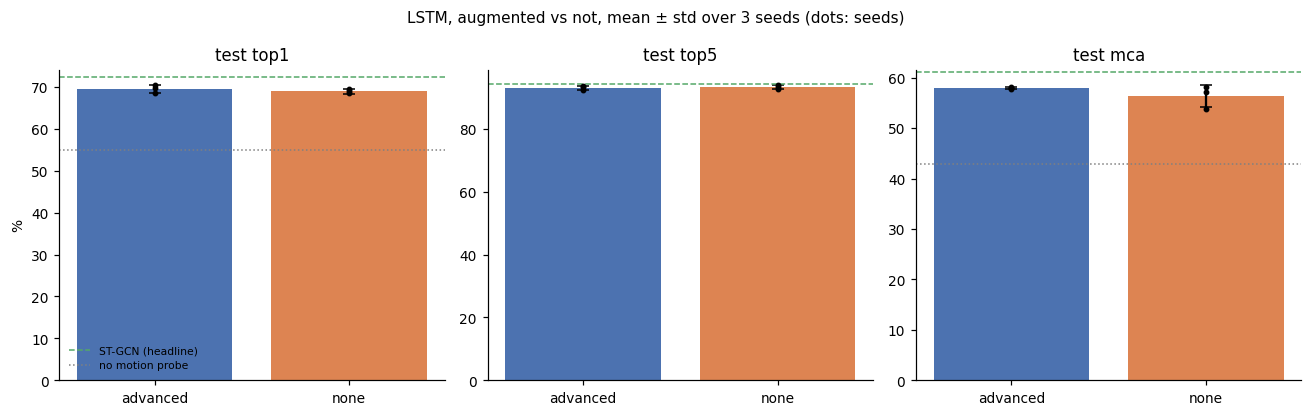

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
x = np.arange(len(CONDITIONS))
for ax, m, stgcn_key, probe_key in zip(axes, ["test_top1", "test_top5", "test_mca"],
                                       ["top1", "top5", "mca"], ["top1", None, "mca"]):
    g = results.groupby("condition")[m]
    means, stds = g.mean().loc[list(CONDITIONS)], g.std().loc[list(CONDITIONS)]
    ax.bar(x, 100 * means, yerr=100 * stds, capsize=4, color=["#4c72b0", "#dd8452"])
    for i, cond in enumerate(CONDITIONS):
        ax.scatter(np.full(len(SEEDS), i), 100 * results.loc[results["condition"] == cond, m], color="black", s=8, zorder=3)
    ax.axhline(100 * STGCN_FINAL[stgcn_key], color="#55a868", ls="--", lw=1, label="ST-GCN (headline)")
    if probe_key:
        ax.axhline(100 * NO_MOTION_PROBE[probe_key], color="grey", ls=":", lw=1, label="no motion probe")
    ax.set_xticks(x, list(CONDITIONS))
    ax.set_title(m.replace("test_", "test ").replace("_", " "))
axes[0].set_ylabel("%")
axes[0].legend(frameon=False, fontsize=7)
fig.suptitle("LSTM, augmented vs not, mean ± std over 3 seeds (dots: seeds)", fontsize=10)
fig.tight_layout()
slog.report_matplotlib_figure("LSTM vs ST-GCN and no motion probe", "test", figure=fig, iteration=0, report_interactive=False)
plt.show()

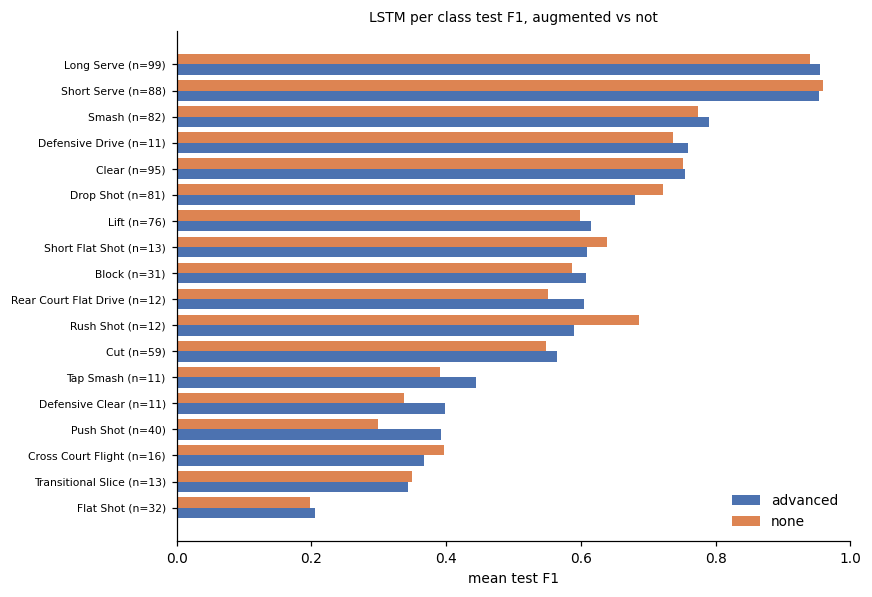

In [8]:
per_class = []
for _, r in results.iterrows():
    pc = pd.read_csv(f"{OUT}/{r['run']}/{r['run']}_per_class.csv")
    pc["condition"] = r["condition"]
    per_class.append(pc)
per_class = pd.concat(per_class)
pivot = per_class.groupby(["class", "condition"])["f1"].mean().unstack()[list(CONDITIONS)]
support = per_class.groupby("class")["support"].first()
order = pivot["advanced"].sort_values().index

fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(order))
ax.barh(y - 0.2, pivot.loc[order, "advanced"], height=0.4, color="#4c72b0", label="advanced")
ax.barh(y + 0.2, pivot.loc[order, "none"], height=0.4, color="#dd8452", label="none")
ax.set_yticks(y, [f"{c} (n={support[c]})" for c in order], fontsize=7)
ax.set_xlabel("mean test F1")
ax.set_xlim(0, 1.0)
ax.legend(frameon=False)
ax.set_title("LSTM per class test F1, augmented vs not", fontsize=9)
fig.tight_layout()
slog.report_matplotlib_figure("LSTM per class F1", "test", figure=fig, iteration=0, report_interactive=False)
plt.show()
slog.report_table("per class F1 by condition", "test", iteration=0, table_plot=pivot.reset_index())
summary.close()

## Reading the result

- LSTM is expected to sit below ST-GCN: it has no explicit skeletal structure, so it has to learn joint
  relationships purely from co-occurrence in the flattened input, which graph convolution gets for free.
  A useful sanity check is that LSTM still clears the no motion probe comfortably; if it did not, something
  would be wrong with the pipeline, not just the model.
- The augmented vs not gap here is the second data point (after ST-GCN) for whether augmentation's benefit
  is model dependent or a property of the data/sampler. If both models show the same pattern (similar top 1,
  augmentation stabilising MCA and macro F1), that is worth stating as a general finding rather than an
  ST-GCN specific one.